# Tarea Semanal 8 — Filtrado No Lineal
**GRUPO 1:** Del Monaco, García Corona, Miranda, Weitzman.

Análisis y Procesamiento de Señales

## Introducción

En la tarea semanal anterior se trabajó con filtros digitales lineales, tanto IIR como FIR. Para que un sistema sea lineal, este debe cumplir con el principio de superposición, es decir, la respuesta del sistema a la suma de varias entradas debe coincidir con la suma de las respuestas a cada una de ellas por separado. Si además es invariante en el tiempo, la respuesta al impulso contiene toda la información necesaria sobre el sistema, así como también lo hace su respuesta en frecuencia.

El ECG captura la actividad eléctrica del corazón y en cada latido presenta una onda P, el complejo QRS y la onda T. En este proyecto se optó por estimar las interferencias en el dominio del tiempo ($\hat{b}[n]$) y se le resta a la señal registrada ($s[n]$):

$$\hat{x}[n] = s[n] - \hat{b}[n]$$

Los estimadores aplicados son no lineales o dependientes de la señal, esto implica que no cumplen con el principio de superposición y por lo tanto no cuentan con una respuesta en frecuencia que los describa.

**Filtro de mediana**

Reemplaza cada muestra por la mediana de una ventana de $L$ muestras:

$$m[n] = \mathrm{med}\,(s[n], s[n-1], \dots, s[n-L+1])$$

La mediana se obtiene ordenando los valores y tomando el central, no es una combinación lineal. Es por esto que la mediana de una suma de señales no es siempre la suma de las medianas.

**Interpolación por splines cúbicos**

Entre la onda P y el complejo QRS, el impulso cardíaco se demora al atravesar el nódulo aurículo-ventricular y la actividad eléctrica es aproximadamente nula. Ese segmento PQ define el nivel isoeléctrico. Lo que se mide en ese tramo es interferencia. Si se toma un punto por latido en ese segmento se obtiene un muestreo no uniforme de la línea de base, a una muestra por latido. Para llevarla a la frecuencia de muestreo del ECG se interpola con un spline cúbico. Con esta herramienta se genera una curva formada por polinomios de tercer grado entre puntos consecutivos, con primera y segunda derivada continuas en las uniones. Como resultado se obtiene una estimación suave que pasa exactamente por los puntos medidos. Como esos puntos se ubican a partir de los latidos detectados en la propia señal, el procedimiento tampoco es un sistema LTI.

**Filtro adaptado**

Se utiliza para detectar los latidos. A diferencia de los dos anteriores, el filtro adaptado en sí es un sistema lineal (un FIR cuya respuesta al impulso es el patrón buscado, invertido en el tiempo); lo no lineal es la etapa de decisión posterior (umbral y búsqueda de máximos).

## Desarrollo

Se carga el archivo, se leen las variables y se grafican los datos provistos.

In [1]:
import os
import urllib.request
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.interpolate import CubicSpline

url_mat = 'https://github.com/franciscoweitzman-cyber/aps_francisco_weitzman/raw/refs/heads/main/TS7/ECG_TP4.mat'
nombre_archivo = 'ECG_TP4.mat'
if not os.path.exists(nombre_archivo):
    urllib.request.urlretrieve(url_mat, nombre_archivo)

# =============================================================================
# Lectura del registro
# =============================================================================
fs_ecg = 1000  # Hz
mat_struct = sio.loadmat(nombre_archivo)

ecg_one_lead_rs = (mat_struct['ecg_lead'] * 1.0).flatten()   # ECG con interferencias (s[n])
N = len(ecg_one_lead_rs)
nn = np.arange(0, N)

hb_1 = mat_struct['heartbeat_pattern1'].flatten()            # latido normal
hb_2 = mat_struct['heartbeat_pattern2'].flatten()            # latido ventricular (ectópico)
qrs_pattern1 = mat_struct['qrs_pattern1'].flatten()          # patrón del complejo QRS (filtro adaptado)
qrs_detections = mat_struct['qrs_detections'].flatten()      # detecciones de referencia


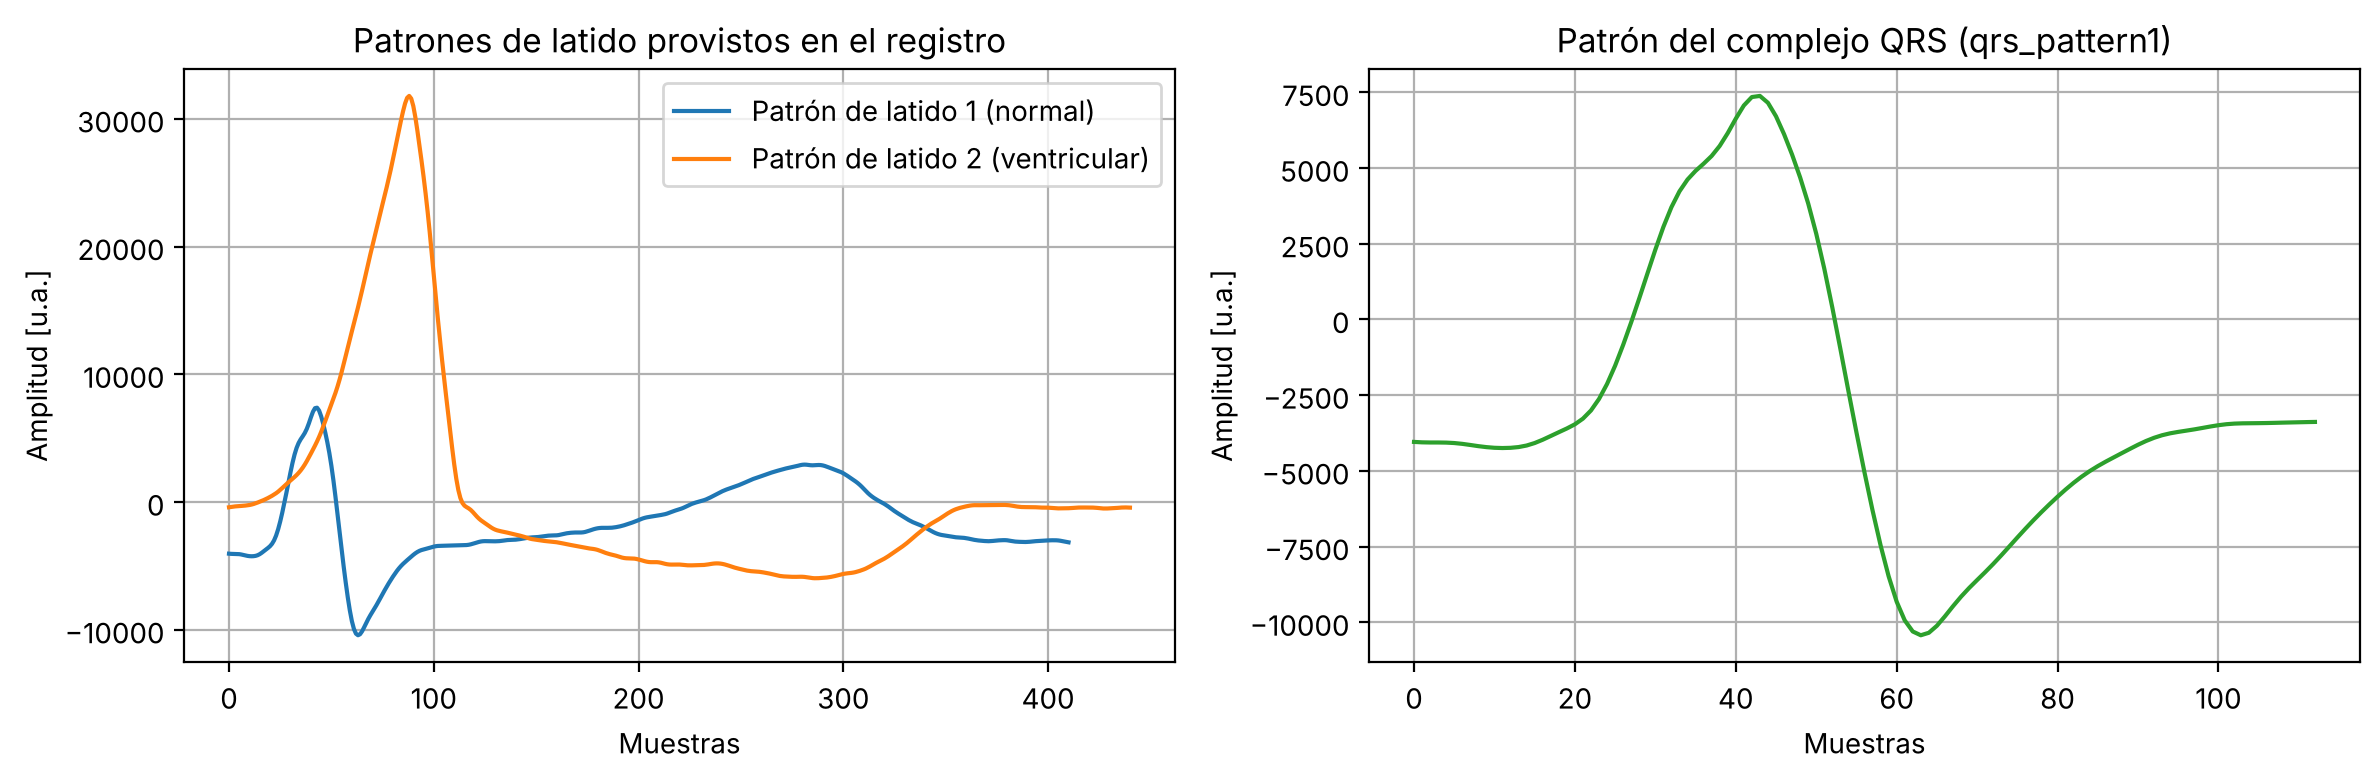

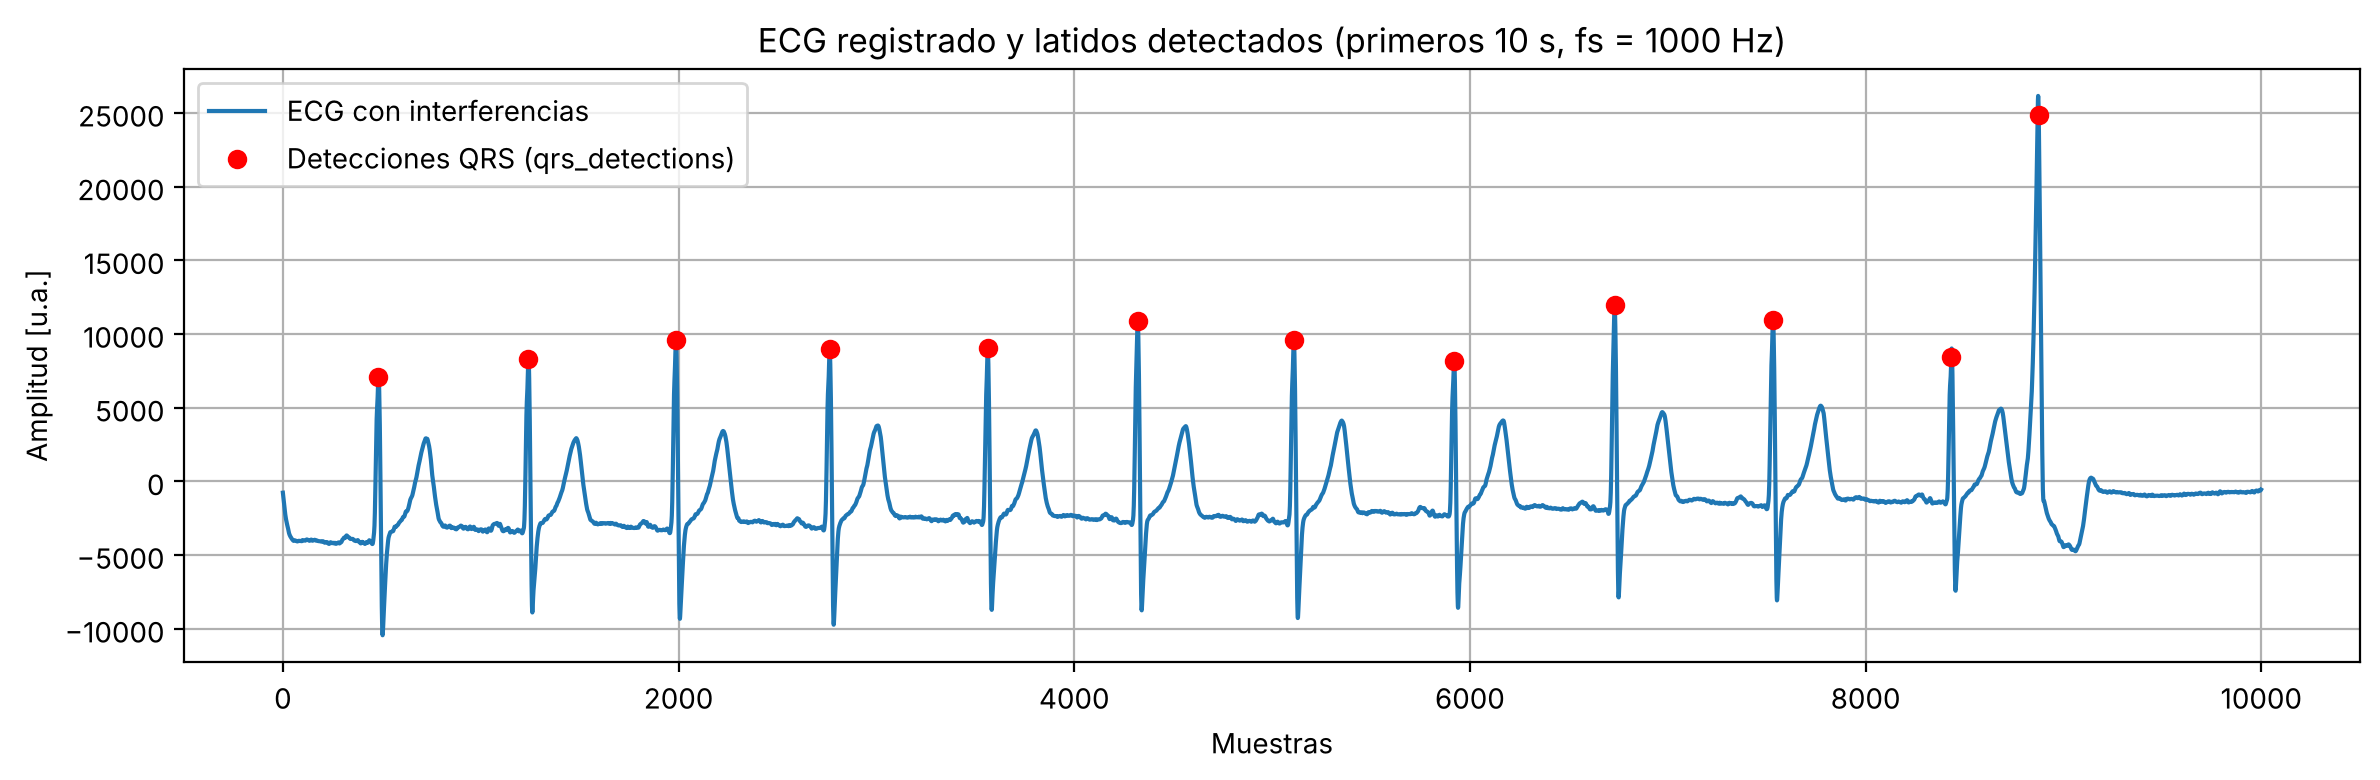

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hb_1, label='Patrón de latido 1 (normal)')
ax[0].plot(hb_2, label='Patrón de latido 2 (ventricular)')
ax[0].set_title('Patrones de latido provistos en el registro')
ax[0].set_xlabel('Muestras'); ax[0].set_ylabel('Amplitud [u.a.]')
ax[0].legend(); ax[0].grid(True)

ax[1].plot(qrs_pattern1, color='C2')
ax[1].set_title('Patrón del complejo QRS (qrs_pattern1)')
ax[1].set_xlabel('Muestras'); ax[1].set_ylabel('Amplitud [u.a.]')
ax[1].grid(True)
plt.tight_layout(); plt.show()

N_plot = 10000
qrs_plot = qrs_detections[qrs_detections < N_plot]

plt.figure(figsize=(12, 4))
plt.plot(nn[:N_plot], ecg_one_lead_rs[:N_plot], label='ECG con interferencias')
plt.plot(qrs_plot, ecg_one_lead_rs[qrs_plot], 'o', color='red', label='Detecciones QRS (qrs_detections)')
plt.title(f'ECG registrado y latidos detectados (primeros {N_plot / fs_ecg:.0f} s, fs = {fs_ecg} Hz)')
plt.xlabel('Muestras'); plt.ylabel('Amplitud [u.a.]')
plt.legend(loc='upper left'); plt.grid(True)
plt.tight_layout(); plt.show()

### 1) Filtro de mediana

La mediana consiste en tomar el percentil 50 de nuestras amplitudes ordenadas, es decir, elige la muestra más probable o popular de una cantidad N de muestras. Por este motivo, si la cantidad de muestras es más que el doble de lo que queremos que pase, la mediana lo va a filtrar. Un ejemplo con un pulso de 3 muestras y una ventana de 7:

`0 0 0 | | | 0 0 0`  

Esa señal tiene 3 valores de interés, si elegimos una mediana de 7 valores, nunca va a llegar a la mitad de tabla, entonces la va a filtrar. Si la muestra 8 fuera mayor a las 3 de interés, también entraría el valor de interés. Esto es una consecuencia de la no linealidad: un filtro lineal atenuaría el pulso pero no lo anularía.

Se aplican dos etapas:

1. Mediana de 200 ms (201 muestras): el QRS dura menos de ~100 ms, es decir, menos de la mitad de la ventana, por lo que es eliminado. Se usa una cantidad impar de muestras para tener la misma cantidad de lecturas antes y después de la muestra central. Queda una señal con las ondas P y T y la línea de base.
2. Mediana de 600 ms (601 muestras) sobre la salida anterior: las ondas P y T duran menos de ~300 ms, es decir, menos de la mitad de esta ventana, por lo que también son eliminadas. Queda la línea de base.

Si se aplicara una única mediana de 600 ms sobre la señal original, los picos del QRS (de gran amplitud) igualmente influirían en el ordenamiento de las muestras; por eso conviene eliminarlos primero con la ventana más corta.

Ambas etapas se comportan, en el sentido de lo que dejan pasar, de forma *similar* a un pasa bajos, pero esto se justifica en el dominio del tiempo (ancho de las estructuras) y no mediante una respuesta en frecuencia, que no existe para un sistema no lineal.

In [4]:
#%% Filtros no lineales
# Mediana
b_200 = sig.medfilt(ecg_one_lead_rs, 201)
b_hat = sig.medfilt(b_200, 601)
ecg_medfilt2 = ecg_one_lead_rs - b_hat
ecg_medfilt = ecg_one_lead_rs - b_200

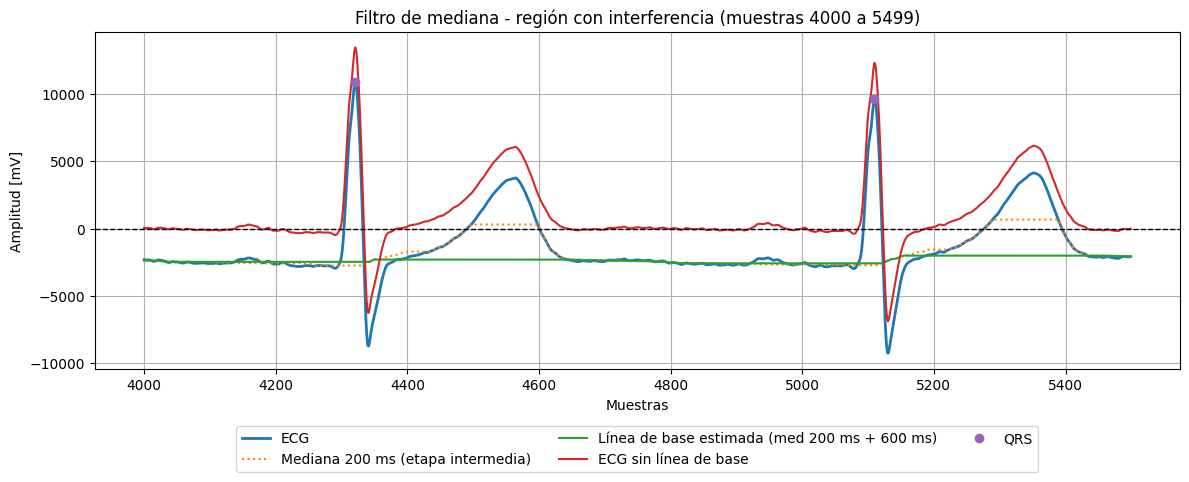

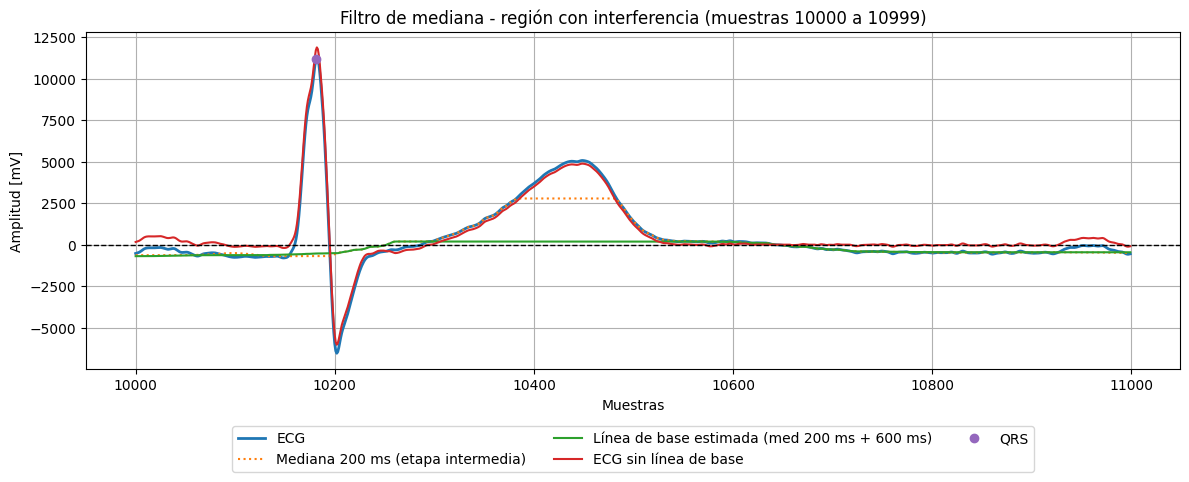

In [5]:
# =============================================================================
#  Gráficos por regiones de interés - Filtro de mediana
# =============================================================================
cant_muestras = N

regs_interes = (
        [4000, 5500],   # muestras
        [10e3, 11e3],   # muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    # Máscara para quedarse solo con los latidos que caen dentro de zoom_region
    mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead_rs[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, b_200[zoom_region], ':', label='Mediana 200 ms (etapa intermedia)')
    plt.plot(zoom_region, b_hat[zoom_region], label='Línea de base estimada (med 200 ms + 600 ms)')
    plt.plot(zoom_region, ecg_medfilt2[zoom_region], label='ECG sin línea de base')

    plt.plot(qrs_detections[mask_qrs], ecg_one_lead_rs[qrs_detections[mask_qrs]], 'o', label='QRS')

    plt.axhline(0, color='k', linestyle='--', linewidth=1)
    plt.title(f'Filtro de mediana - región con interferencia (muestras {int(zoom_region[0])} a {int(zoom_region[-1])})')
    plt.xlabel('Muestras')
    plt.ylabel('Amplitud [mV]')
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

En los tramos cortos se observa que la etapa intermedia (línea punteada) ya elimina el QRS pero todavía "arrastra" parte de las ondas P y T, mientras que la segunda etapa (línea verde) deja una línea de base suave. Al restarla, el ECG queda centrado en torno al nivel isoeléctrico (línea de trazos en 0).

Ahora se analizan tramos de los minutos 5, 12 y 15, que presentan distintos grados de interferencia (en el minuto 12 la línea de base cae hasta aproximadamente −30000 u.a.).

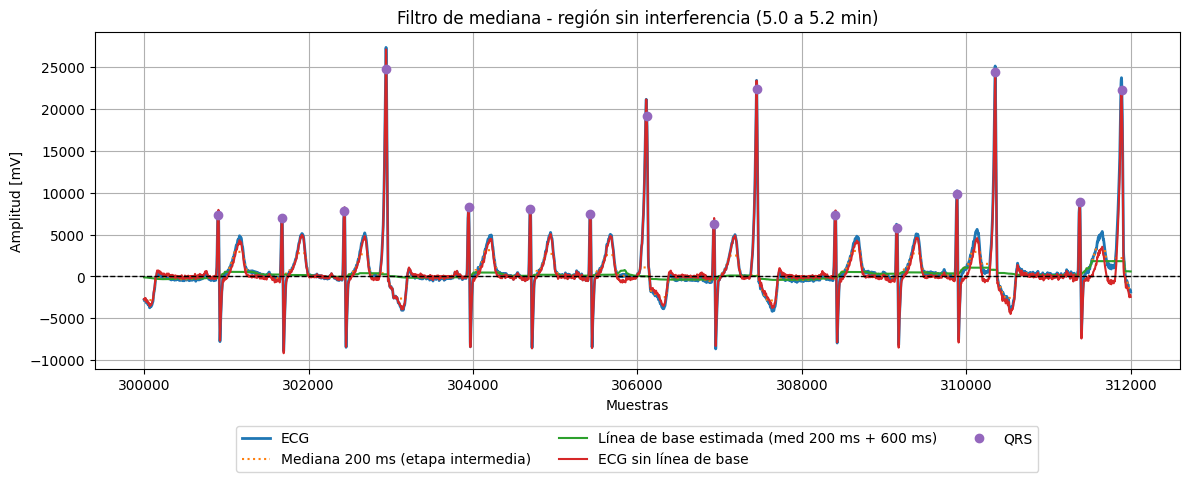

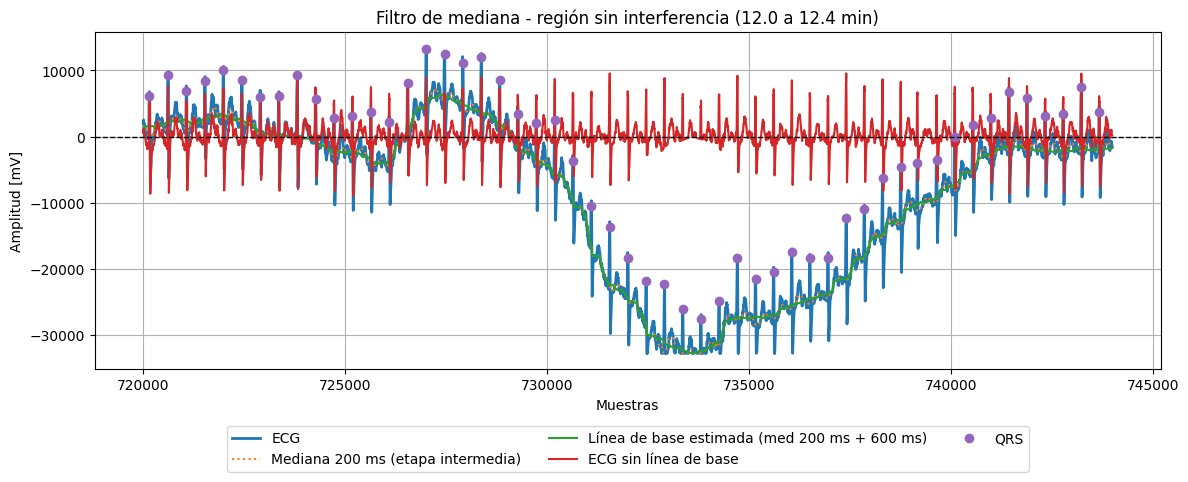

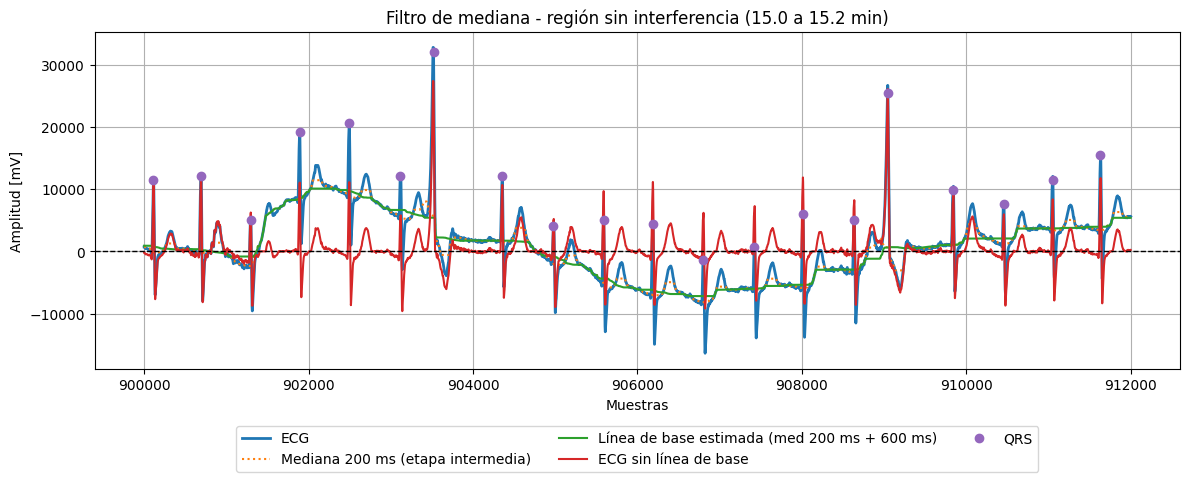

In [6]:
#################################
# Regiones de interés sin ruido #
#################################

regs_interes = (
        np.array([5, 5.2]) *60*fs_ecg, # minutos a muestras
        np.array([12, 12.4]) *60*fs_ecg, # minutos a muestras
        np.array([15, 15.2]) *60*fs_ecg, # minutos a muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    # Máscara para quedarse solo con los latidos que caen dentro de zoom_region
    mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead_rs[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, b_200[zoom_region], ':', label='Mediana 200 ms (etapa intermedia)')
    plt.plot(zoom_region, b_hat[zoom_region], label='Línea de base estimada (med 200 ms + 600 ms)')
    plt.plot(zoom_region, ecg_medfilt2[zoom_region], label='ECG sin línea de base')

    plt.plot(qrs_detections[mask_qrs], ecg_one_lead_rs[qrs_detections[mask_qrs]], 'o', label='QRS')

    plt.axhline(0, color='k', linestyle='--', linewidth=1)
    plt.title(f'Filtro de mediana - región sin interferencia ({zoom_region[0]/60/fs_ecg:.1f} a {zoom_region[-1]/60/fs_ecg:.1f} min)')
    plt.xlabel('Muestras')
    plt.ylabel('Amplitud [mV]')
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

La mediana de dos etapas sigue correctamente la deriva lenta, incluso la caída grande del minuto 12. Se observa también que el ECG filtrado queda alineado con el cero salvo en los latidos donde la mediana "sigue" parcialmente a la onda T (por ejemplo en el minuto 15), lo que es una limitación del método.

Para justificar la necesidad de la segunda etapa se compara a continuación qué ocurre si se resta solamente la mediana de 200 ms:

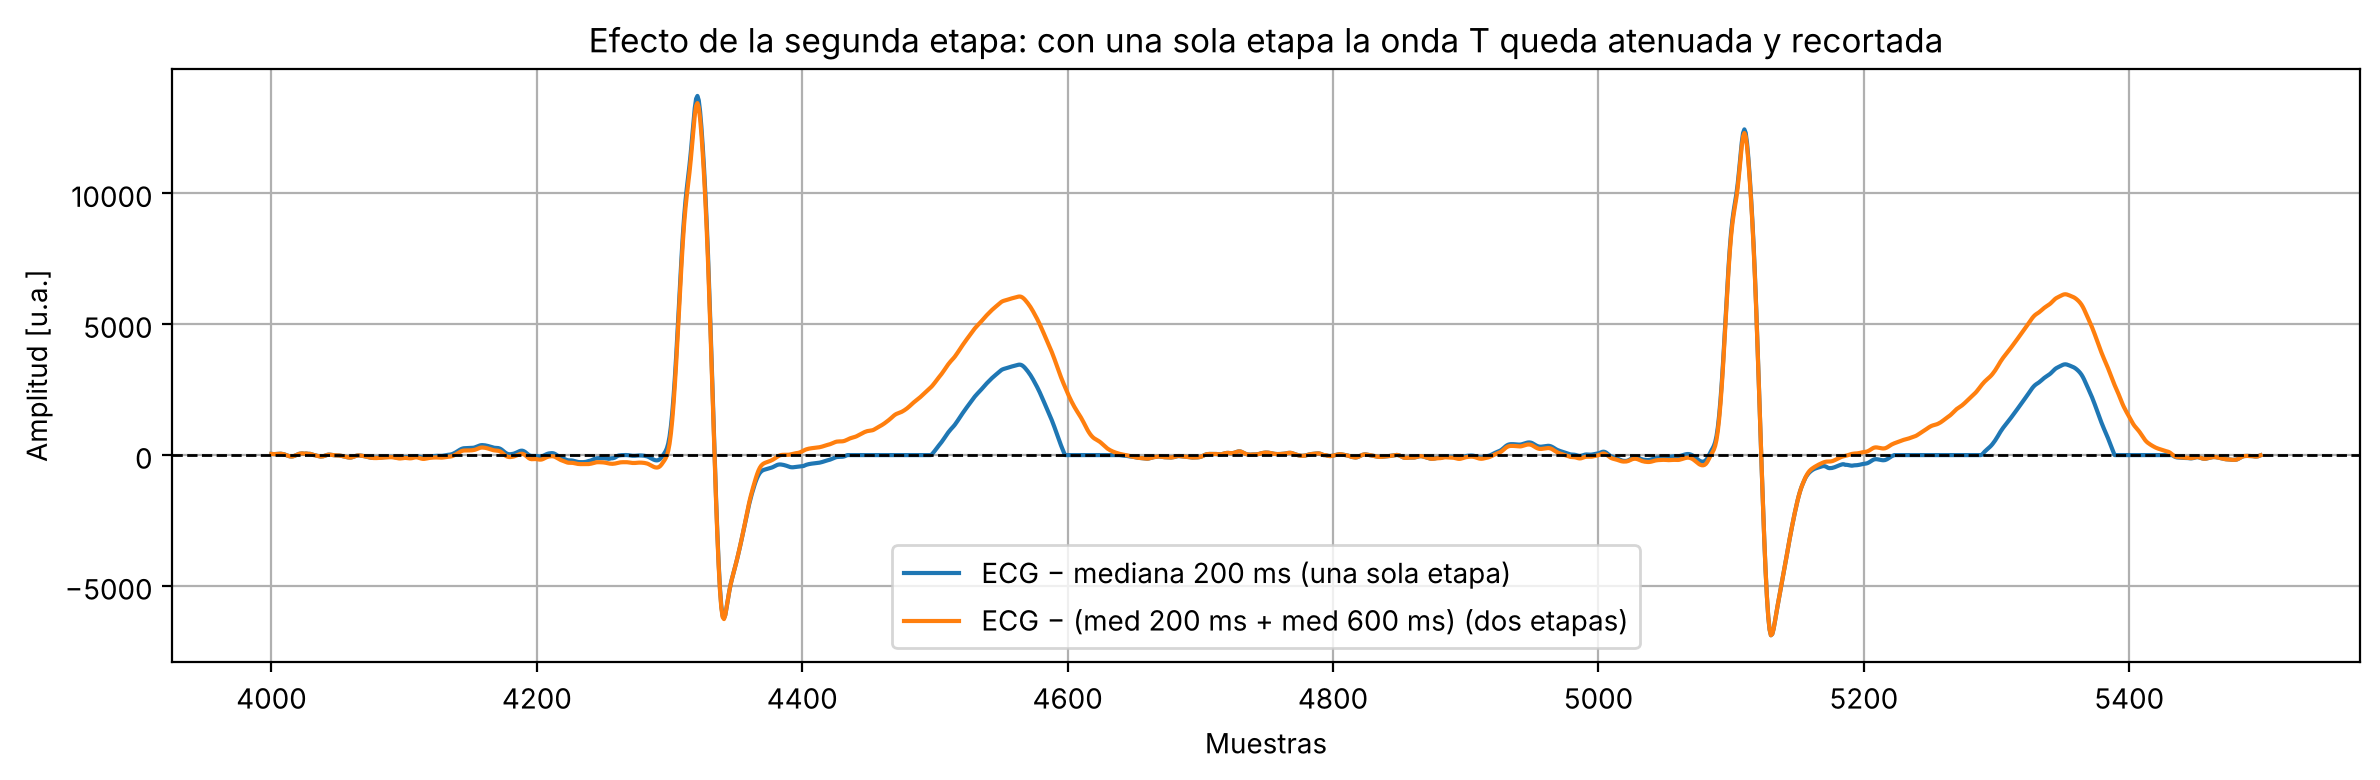

In [6]:
zr = np.arange(4000, 5500)
plt.figure(figsize=(12, 4))
plt.plot(zr, ecg_medfilt[zr], label='ECG − mediana 200 ms (una sola etapa)')
plt.plot(zr, ecg_medfilt2[zr], label='ECG − (med 200 ms + med 600 ms) (dos etapas)')
plt.axhline(0, color='k', linestyle='--', linewidth=1)
plt.title('Efecto de la segunda etapa: con una sola etapa la onda T queda atenuada y recortada')
plt.xlabel('Muestras'); plt.ylabel('Amplitud [u.a.]')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

Con una sola etapa, la mediana de 200 ms deja pasar parte de las ondas P y T hacia la estimación de la línea de base (la onda T dura ~200 ms, es decir, no es lo bastante angosta para ser eliminada por esa ventana). Al restarla, la onda T queda atenuada y recortada en el ECG resultante (en el gráfico, su amplitud baja de ~6000 a ~3500 u.a.), con lo que se pierde información diagnóstica. Con la mediana de 600 ms sobre la salida de la primera, la línea de base queda libre de P y T y la morfología del latido se conserva.

### 2) Interpolación mediante splines cúbicos

Para estimar la línea de base con splines cúbicos se aprovecha que, en el segmento PQ, la actividad eléctrica del corazón es aproximadamente nula: cualquier nivel medido ahí corresponde a la interferencia y no al ECG. Se toma entonces un punto por latido en ese segmento.

Las detecciones `qrs_detections` marcan la posición $n_i$ del pico R de cada latido. A partir de ella se anticipa un tiempo $n_0$ para ubicarse antes del QRS, de manera de no incluir la onda Q. Se eligió una ventana de 20 ms (20 muestras, ya que $f_s$ = 1000 Hz) que va desde 60 ms hasta 40 ms antes del pico R. En cada latido se promedian las muestras de esa ventana, lo que reduce el efecto del ruido de alta frecuencia sobre el valor medido. El resultado es el conjunto de puntos

$$\mathcal{S} = \{(m_i,\ s(m_i))\ |\ i = 1, 2, \dots, Q\}$$

donde $m_i$ es el centro de la ventana de cada latido (50 ms antes del pico R) y $Q = 1903$ es la cantidad de latidos del registro. Como hay una muestra por latido, la línea de base queda muestreada de forma no uniforme, a aproximadamente 1 punto por segundo, lo que alcanza para representar interferencias de menos de 0.5 Hz.

Para llevar esos puntos a la frecuencia de muestreo del ECG se interpola con un spline cúbico (`CubicSpline` de `scipy.interpolate`) evaluado en las $N$ muestras de la señal:

$$\hat{b}[n] = \mathrm{spline}_3(\mathcal{S},\ n)\ |\ n = 1, 2, \dots, N$$

Finalmente, la estimación se resta al ECG registrado: $\hat{x}[n] = s[n] - \hat{b}[n]$.

In [7]:
#%%Splines cúbicos
start_win = qrs_detections-60
end_win = qrs_detections-40
pq_hat = np.array([ np.mean(ecg_one_lead_rs[a:b]) for a,b in zip(start_win, end_win) ])
pq_t_hat = np.array([ np.mean([a,b]) for a,b in zip(start_win, end_win) ])


b_spline = CubicSpline(pq_t_hat,pq_hat)
ecg_spline = ecg_one_lead_rs - b_spline(nn)

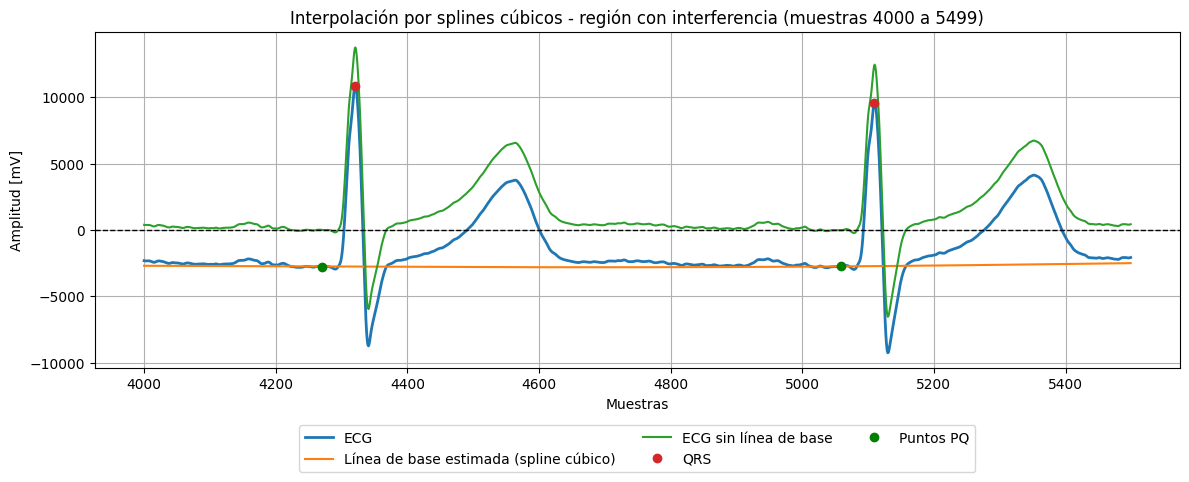

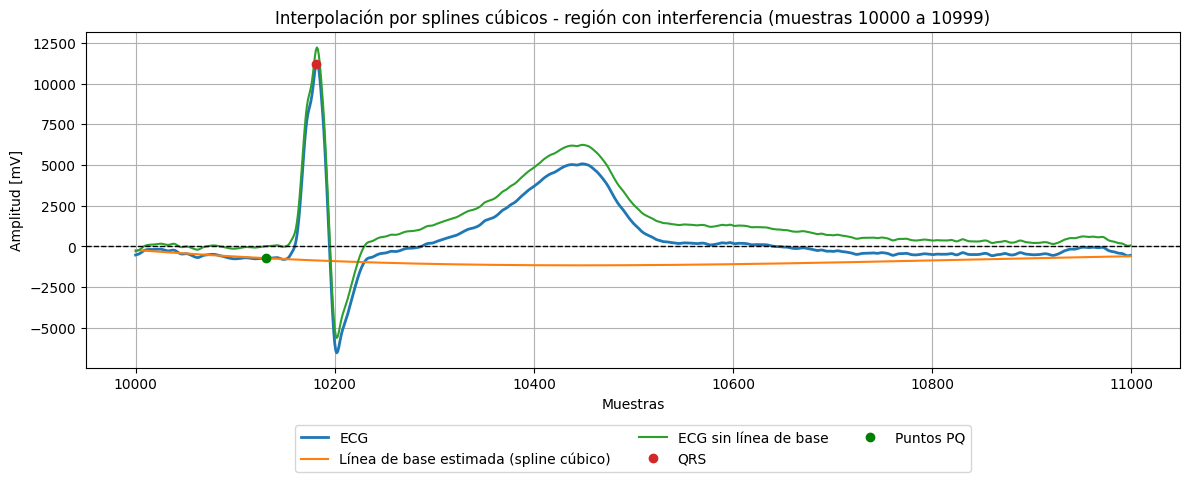

In [8]:
##########################################
# Gráficos Regiones de interés con ruido #
##########################################

cant_muestras = N

regs_interes = (
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    # Máscaras para filtrar solo los puntos que caen dentro de zoom_region
    mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])
    mask_pq  = (pq_t_hat >= zoom_region[0]) & (pq_t_hat <= zoom_region[-1])

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead_rs[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, b_spline(zoom_region), label='Línea de base estimada (spline cúbico)')
    plt.plot(zoom_region, ecg_spline[zoom_region], label='ECG sin línea de base')

    plt.plot(qrs_detections[mask_qrs], ecg_one_lead_rs[qrs_detections[mask_qrs]], 'o', label='QRS')
    plt.plot(pq_t_hat[mask_pq], pq_hat[mask_pq], 'og', label='Puntos PQ')

    plt.axhline(0, color='k', linestyle='--', linewidth=1)
    plt.title(f'Interpolación por splines cúbicos - región con interferencia (muestras {int(zoom_region[0])} a {int(zoom_region[-1])})')
    plt.xlabel('Muestras')
    plt.ylabel('Amplitud [mV]')
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
    plt.tight_layout()
    plt.show()

En los gráficos se observa que el spline (línea de base estimada) pasa exactamente por los puntos PQ (puntos verdes) y entre ellos genera una curva suave que sigue la deriva lenta del registro. Al restarla, el ECG queda centrado en torno a cero en el segmento PQ, que es justamente el nivel isoeléctrico que se quería recuperar.

Este método depende de las detecciones de latidos: si un latido estuviera mal detectado, la ventana caería en otra parte de la señal y el punto resultante sería erróneo, y el spline lo reproduciría exactamente. En cambio, a diferencia de la mediana, no depende del ancho de las ondas P y T, y tiene un costo computacional muy bajo, porque trabaja con ~1900 puntos en vez de ordenar ventanas de cientos de muestras para cada muestra del registro.

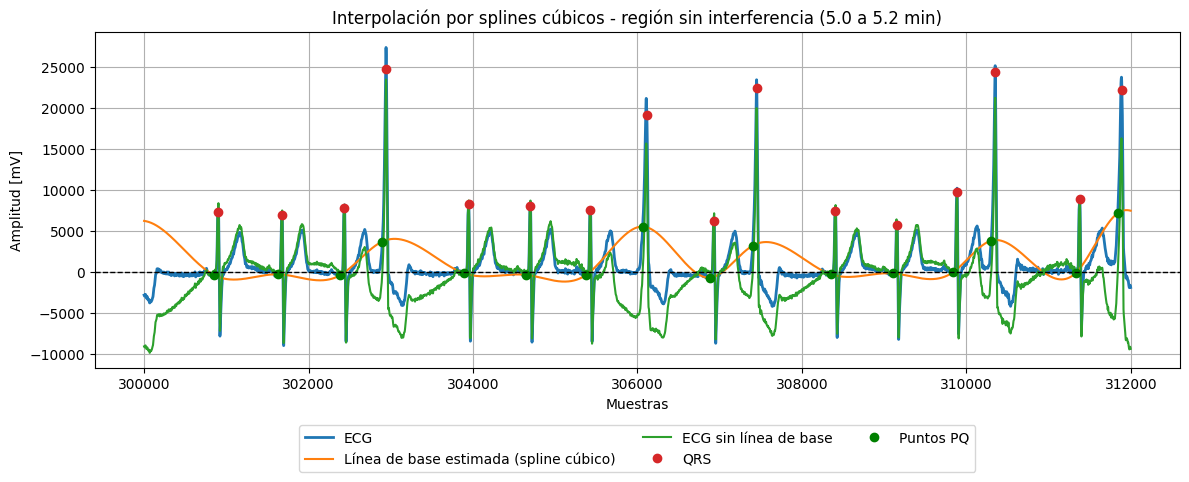

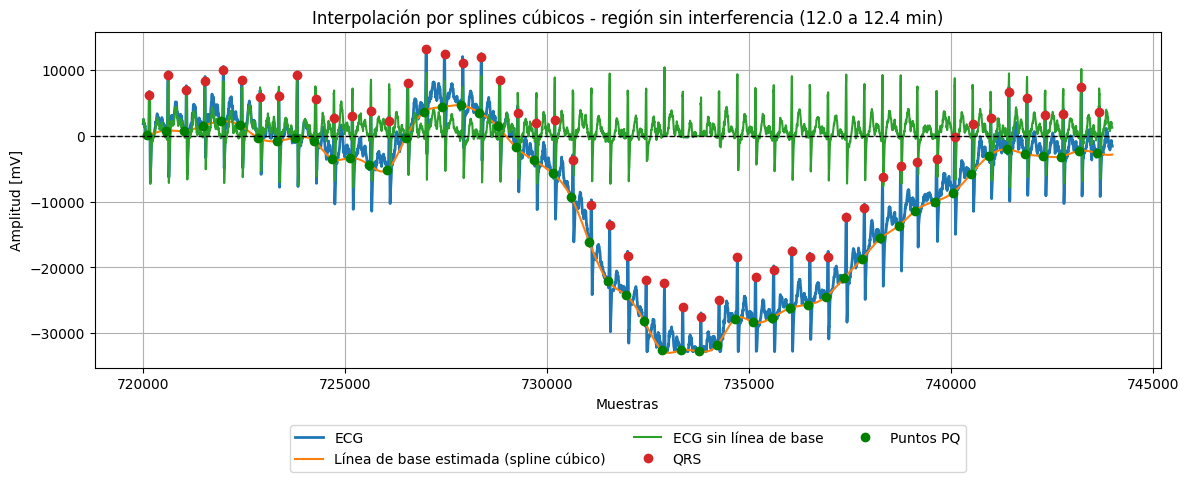

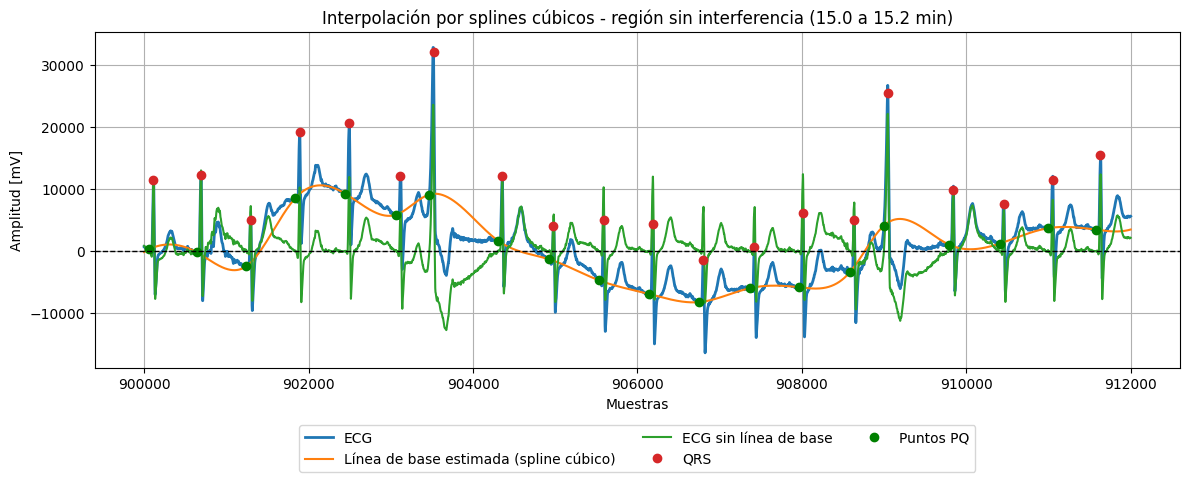

In [9]:
##########################################
# Gráficos Regiones de interés sin ruido #
##########################################

regs_interes = (
        np.array([5, 5.2]) *60*fs_ecg, # minutos a muestras
        np.array([12, 12.4]) *60*fs_ecg, # minutos a muestras
        np.array([15, 15.2]) *60*fs_ecg, # minutos a muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    # Máscaras para filtrar solo los puntos que caen dentro de zoom_region
    mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])
    mask_pq  = (pq_t_hat >= zoom_region[0]) & (pq_t_hat <= zoom_region[-1])

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead_rs[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, b_spline(zoom_region), label='Línea de base estimada (spline cúbico)')
    plt.plot(zoom_region, ecg_spline[zoom_region], label='ECG sin línea de base')

    plt.plot(qrs_detections[mask_qrs], ecg_one_lead_rs[qrs_detections[mask_qrs]], 'o', label='QRS')
    plt.plot(pq_t_hat[mask_pq], pq_hat[mask_pq], 'og', label='Puntos PQ')

    plt.axhline(0, color='k', linestyle='--', linewidth=1)
    plt.title(f'Interpolación por splines cúbicos - región sin interferencia ({zoom_region[0]/60/fs_ecg:.1f} a {zoom_region[-1]/60/fs_ecg:.1f} min)')
    plt.xlabel('Muestras')
    plt.ylabel('Amplitud [mV]')
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
    plt.tight_layout()
    plt.show()

El spline pasa exactamente por los puntos PQ (puntos verdes) y entre ellos genera una curva suave. Como hay un punto por latido (aprox. 1 por segundo), la línea de base queda muestreada a ~1 Hz, lo que alcanza para representar interferencias de menos de 0.5 Hz.

### Filtro adaptado (matched filter)

El filtro adaptado sirve para detectar en una señal una forma de onda conocida, el patrón $p[n]$ de $L$ muestras (acá, el complejo QRS: `qrs_pattern1`). Si el ruido es blanco, el filtro que maximiza la relación señal-ruido en el instante en que aparece el patrón es el FIR cuya respuesta al impulso es el patrón invertido en el tiempo:

$$h[n] = p[L-1-n]$$

Filtrar con $h$ equivale a correlacionar la señal con el patrón: la salida presenta un máximo cada vez que el ECG se parece al QRS. Como el filtro es causal, el máximo aparece cuando el patrón termina de pasar, con un retardo constante de $L-1-r_0$ muestras ($r_0$ es la posición del pico R en el patrón), que se compensa al ubicar los latidos. Luego, un umbral y la búsqueda de máximos (con una distancia mínima entre ellos) definen las detecciones.

Su respuesta en frecuencia es $H(\omega)=P^*(\omega)\,e^{-j\omega(L-1)}$, con $|H(\omega)|=|P(\omega)|$. Como el QRS no es simétrico, $h[n]$ tampoco lo es y **el filtro no tiene fase lineal**. Es lo que hace que todas las componentes del patrón se alineen en un único instante, pero deforma la señal: sirve para detectar latidos, no para conservar su forma.

In [10]:
#%% Filtro adaptado
qrs_pattern1 = mat_struct['qrs_pattern1'].flatten()

# Patrón sin valor medio (así la deriva lenta no aporta a la salida)
patron = qrs_pattern1 - np.mean(qrs_pattern1)

# Respuesta al impulso del filtro adaptado: el patrón invertido en el tiempo
h = patron[::-1]

# Se filtra el ECG sin línea de base con h
y = sig.lfilter(h, 1, ecg_spline)

# El filtro demora la salida: el máximo aparece cuando el patrón termina de pasar,
# y no cuando pasa por el pico R. Se compensa esa demora.
pico_R_patron = np.argmax(qrs_pattern1)
demora = len(patron) - 1 - pico_R_patron

# Detección de latidos: máximos de la salida que superan un umbral
umbral = 2 * np.std(y)
picos, _ = sig.find_peaks(y, height=umbral, distance=int(0.25*fs_ecg))
qrs_mf = picos - demora

# Comparación con qrs_detections (tolerancia de 50 ms)
tol = int(0.05*fs_ecg)
TP = 0
for q in qrs_detections:
    if np.min(np.abs(qrs_mf - q)) <= tol:
        TP += 1
FN = len(qrs_detections) - TP
FP = len(qrs_mf) - TP
sens = TP / (TP + FN)
vpp = TP / (TP + FP)

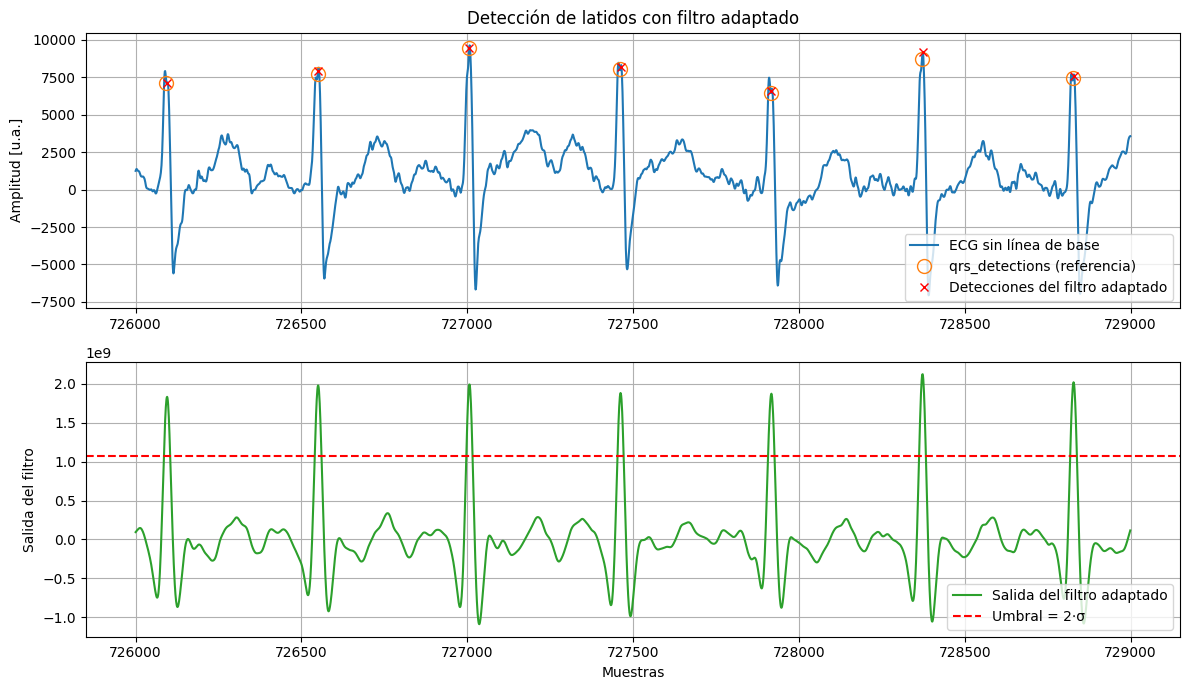

In [11]:
# Salida del filtro adaptado y detecciones en una región con mucha interferencia (minuto 12)
zoom_region = np.arange(int(12.1*60*fs_ecg), int(12.15*60*fs_ecg))
mask_qrs = (qrs_detections >= zoom_region[0]) & (qrs_detections <= zoom_region[-1])
mask_mf = (qrs_mf >= zoom_region[0]) & (qrs_mf <= zoom_region[-1])

plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(zoom_region, ecg_spline[zoom_region], label='ECG sin línea de base')
plt.plot(qrs_detections[mask_qrs], ecg_spline[qrs_detections[mask_qrs]], 'o', mfc='none', ms=10, label='qrs_detections (referencia)')
plt.plot(qrs_mf[mask_mf], ecg_spline[qrs_mf[mask_mf]], 'x', color='r', label='Detecciones del filtro adaptado')
plt.title('Detección de latidos con filtro adaptado')
plt.ylabel('Amplitud [u.a.]')
plt.legend(loc='lower right')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(zoom_region, y[zoom_region + demora], color='C2', label='Salida del filtro adaptado')
plt.axhline(umbral, color='r', linestyle='--', label='Umbral = 2·σ')
plt.xlabel('Muestras')
plt.ylabel('Salida del filtro')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

En los gráficos se ve que, incluso en el minuto 12 (con la línea de base desplazada más de 30000 u.a.), la salida del filtro supera el umbral solo en los latidos y las detecciones coinciden con `qrs_detections`. Para cuantificarlo se consideró verdadero positivo (TP) a toda detección a menos de 50 ms de un latido de referencia, falso negativo (FN) al latido sin detección y falso positivo (FP) a la detección sin latido, y se calcularon la sensibilidad $TP/(TP+FN)$ y el valor predictivo positivo $TP/(TP+FP)$.

Como limitaciones, la salida es proporcional a la amplitud del latido (acá los R varían entre ~5000 y ~30000 u.a.), por lo que un umbral fijo puede dejar sin detectar a los más chicos, y los latidos de morfología distinta a `qrs_pattern1`, como los ventriculares, dan una correlación menor y podrían perderse.

**Análisis de los resultados**

Incluso en el minuto 12, donde la línea de base se desplaza más de 30000 u.a., la salida del filtro presenta un máximo bien definido en cada latido que supera el umbral, mientras que el resto del ECG (ondas P y T, ruido) queda por debajo, y las detecciones coinciden con las de `qrs_detections`.

## Conclusiones

Podemos apreciar que los tres métodos implementados son no lineales o dependientes de la señal, por lo que no cuentan con una respuesta en frecuencia que los describa. Esto los diferencia de los filtros IIR y FIR de la TS7. Tanto la mediana como el spline permiten estimar la línea de base en el dominio del tiempo y restarla de la señal. El filtro adaptado, en cambio, no se usa para eliminar interferencias sino para detectar latidos. Es un FIR, pero su respuesta al impulso es el patrón invertido, que no es simétrico, por lo que no tiene fase lineal. Esto deforma la señal de salida, pero no es un inconveniente porque lo que interesa es la posición del máximo, y el retardo constante que introduce se compensa al ubicar los latidos.

La mediana tiene la ventaja de no depender de ninguna detección previa, pero requiere ordenar ventanas de 201 y 601 muestras para cada muestra del registro, por lo que su costo computacional es alto, y sus ventanas largas pueden contaminarse con las ondas P y T. El spline estima directamente el nivel isoeléctrico a partir de un punto por latido, con un costo computacional mucho menor, pero depende de que los latidos estén bien detectados y de la correcta elección de la ventana PQ. Además, ambos métodos necesitan muestras posteriores a la que se está procesando (la mediana por usar una ventana centrada y el spline por interpolar entre latidos), por lo que no pueden aplicarse en tiempo real sin introducir una demora.

En cuanto a nuestros resultados, tanto la mediana como el spline siguieron el movimiento de la línea de base y centraron el ECG en torno a cero, incluso en el minuto 12, donde la línea de base se desplaza más de 30000 u.a., y conservaron la forma de los latidos. Por su parte, el filtro adaptado detectó los latidos con una sensibilidad y un valor predictivo positivo de 99,84 %. Su principal limitación es que la salida es proporcional a la amplitud del latido, por lo que un umbral fijo puede dejar sin detectar a los más chicos, y que los latidos de morfología distinta al patrón, como los ventriculares, dan una correlación menor.

Con esta información podemos concluir que la elección de un método por sobre otro depende de lo que se desee priorizar: la independencia de las detecciones y la simplicidad en el caso de la mediana, el bajo costo computacional en el caso del spline, o la robustez de la detección frente al ruido en el caso del filtro adaptado.